Simulating hodgkin huxley neurons in C++
This is just a quick bit of testing, but may provide a base for an improved version of the simulator

Basic features:
Single compartment conductance based neurons
Voltage and ligand gating 
Simple conductance based synapses

Conductance based neurons:
Resting membrane potential defined in terms of membrane conductances for each ion # Nernst potentials for Na, K, Cl, and Ca, and 
Monoexponential gating defined in terms of Vhalf, Vk, theta0 theta1 sig0 k0

The fundamental principle guiding the simulation code is that we avoid any conditional (if) statements. This means we end up doing a lot of unnecessary calculations, but it allows us to run the code on a GPU which more thank makes up for it. 
I dont like the idea of current injection, or even of bias currents. I think its unphysiological to have a constant current that does not changed based on neural or external conditions.  

Extra features:
Multicompartments
ChatGPT compile python to c++
Delays
Gap junctions 
Short term plasticity
Long term calcium based plasticity 

In [1]:
from auxillaryFunctions import *

# build_dir,configType = "build", "Debug"
# moduleDir = os.path.join(build_dir, configType)
# if moduleDir not in sys.path:
#     sys.path.append(moduleDir)

# import cathalTest
#we use inverse slope, 1/k, whereas most of the literature uses k. This is because we want to avoid division in the sigmoid function

def addSpikerToSystem(ac,spkrDict,spikerPreNeuron):
    #all the stuff normally realting to neural spiking gets added here
    #spikes can be triggered either randomly and/or by spike thresholding in the presynaptic neuron
    #the simulation code checks for both conditions. To have only random spiking, choose an aribitrary presynaptic neuron (e.g. neuron 0),
    #and set the spikeNeuronScale = 0. To have only neuron spiking, set spikerProbability to 0.
    ac["spikerPreNeuron"].append(spikerPreNeuron)
    ac["spikerNeuronScale"].append(spkrDict["spikerNeuronScale"]) #0 for random, 1 for neuron based and random
    ac["spikerProbability"].append(spkrDict["spikerProbability"]) #set to 0 to remove random spiking

def genChannelData(neuronData,spikerData,synapseData,diffusionList,TS):
    #new keys: spikerPreNeuron, spikerNeuronScale, nSpikers, channelPreSpiker (used to be preNeuron)
    allChannelData = {key:[] for key in genOpenGate().keys()}
    listKeys = ["postNeuron","channelPreSpiker","conductance","Erev","CaCurrent","inputDelay", #channel parameters
                "efficacy","conductanceGain","rate","gammaP","gammaD","thetaP","thetaD", #plasticity parameters
                "diffPostNeuron","diffPreNeuron","diffRate","current","name",#diffusion parameters
                "spikerPreNeuron","spikerNeuronScale","spikerProbability"] #spiker parameters 

    valueKeys = ["nChannels","nDiffusiveConnections","nSpikers","nNeurons"]

    for key in listKeys:
        allChannelData[key] = []
    for key in valueKeys:
        allChannelData[key] = 0

    #efficacy, conductanceGain, rate, gammaP, gammaD, thetaP, thetaD,
    def addDiffusiveConnection(preNeuron,postNeuron,diffusionRate):
        allChannelData["diffPostNeuron"].append(postNeuron)
        allChannelData["diffPreNeuron"].append(preNeuron)
        allChannelData["diffRate"].append(diffusionRate)
        allChannelData["nDiffusiveConnections"]+=1

    nNeurons = len(neuronData)
    allChannelData["nNeurons"] = nNeurons
    nSpikers = 0
    allChannelData["biasCurrents"] = []
    for ind,data in enumerate(neuronData):
        spkrData = data["spikerData"]
        if spkrData is not None:
            addSpikerToSystem(allChannelData,spkrData,ind)
            nSpikers +=1
        allChannelData["biasCurrents"].append(data["neuronData"]["bias"])
        for channel,channelData in data["channelData"].items():
            #if channel not in ["neuronData","spikerData"]: #info about the neuron specifically, separate from the channel
                addBasicChannelToSystem(allChannelData,ind,channelData)

    for spkrData in spikerData:
        addSpikerToSystem(allChannelData,spkrData,0)

    nSpikers +=len(spikerData)
    allChannelData["nSpikers"] = nSpikers
    allChannelData["writeIndex"] = np.zeros(nSpikers,dtype=np.int32)
    maxDelayInt = 1 #default to 1
    for group in synapseGroups:
        for conn in group:
            pre,post = conn["pre"],conn["post"]
            synapseData = conn["synapse"]
            delay = conn["delay"] #in ms
            delayInt = int(np.ceil(delay/TS))
            maxDelayInt = max(delayInt,maxDelayInt)
            assert 0<=pre<nSpikers and 0<=post<nSpikers, f"edge out of range {pre},{post}"
            addSynapseToSystem(pre,post,synapseData,delayInt,allChannelData)


    for (e0,e1,diffusionRate) in diffusionList:
        assert e0<nNeurons and e1<nNeurons, f"edge out of range {e0},{e1}"
        addDiffusiveConnection(e0,e1,diffusionRate)
    
    allChannelData["maxDelayInt"] = maxDelayInt
    allChannelData["voltages"] = -75*np.ones(nNeurons,dtype = np.float32) + 1*np.arange(0,nNeurons,dtype=np.float32)
    allChannelData["calciumVals"] = np.zeros(nNeurons,dtype = np.float32)
    # allChannelData["biasCurrents"] = bias*np.ones(nNeurons,dtype = np.float32)
    allChannelData["spikeVals"] = np.zeros(nSpikers,dtype = np.float32)
    allChannelData["netCurrent"] = np.zeros(nNeurons,dtype = np.float32)
    allChannelData["netCaCurrent"] = np.zeros(nNeurons,dtype = np.float32)
    allChannelData["spikeBuffer"] = np.zeros((nSpikers,maxDelayInt),dtype=bool) #we could use float if we wanted some kind of scaling, but for perf we use bool

    intKeys = ["channelPreSpiker","postNeuron", "nChannels","diffPostNeuron",
               "diffPreNeuron","nDiffusiveConnections","writeIndex",
               "maxDelayInt","inputDelay","nNeurons","nSpikers","spikerPreNeuron"]
    
    nonArrayKeys = ["nNeurons","maxDelayInt","nChannels","nDiffusiveConnections","name","nSpikers"]
    for key in allChannelData.keys():
        val = allChannelData[key]
        if key in intKeys: arrDtype = np.int32
        else: arrDtype = np.float32

        if key in nonArrayKeys:
            pass
        elif type(val) in [list,tuple]:
            allChannelData[key] = np.ascontiguousarray(val,dtype = arrDtype)
        elif type(val)  == np.ndarray:
            allChannelData[key] = np.ascontiguousarray(val,dtype = val.dtype)
        else:
            print(f"Warning {key} is not a list or tuple") 
    
    return allChannelData




# def genSynapseGroup(preRange,postRange,nSynapses,synapse,delay):
#     preVals = np.random.randint(preRange[0],preRange[1],nSynapses)
#     postVals = np.random.randint(postRange[0],postRange[1],nSynapses)
#     synapseData = [{"pre":e0,"post":e1,"synapse":deepcopy(synapse),"delay":delay} for e0,e1 in zip(preVals,postVals)]
#     return synapseData


In [18]:
#neurons
STNchannels = np.load(r"tools\translatedSTNchannels2.npy",allow_pickle=True).item()
GPechannels = np.load(r"tools\translatedGPechannels2.npy",allow_pickle=True).item()
STNbias = -2.1
GPeBias = -0.23

class Neuron():
    def __init__(self,name,index,neuronType,AISchannels,AISbias,nDendrites=0,denderiteInfo=None):
        neuronTypeToSynapseList = {"excitatory":["AMPA","NMDA"],
                                   "inhibitory":["GABA"]}
        
        self.id = index
        self.name=name
        self.outgoingSynapses = neuronTypeToSynapseList[neuronType]
        self.AIS = {"channels":AISchannels,"bias":AISbias} #axon initial segment. Basically the thing that modelled in a single compartment neuron
        self.dendrites = {}
        for i in range(nDendrites):
            self.dendrites[i] = deepcopy(denderiteInfo)
        self.spiker = {"spikerNeuronScale":1,"spikerProbability":0}
        
class Spiker():
    def __init__(self,name,index,neuronType,spikeRate,TS):
        neuronTypeToSynapseList = {"excitatory":["AMPA","NMDA"],
                                   "inhibitory":["GABA"]}
        
        self.id = index
        self.name=name
        self.outgoingSynapses = neuronTypeToSynapseList[neuronType]
        self.spiker = {"spikerNeuronScale":0,"spikerProbability":spikeRate*TS/1000.0}
        

TS = 0.05  
nSTN,nGPe = 2,3
nCTX,nMSN = 3,4
CTXrate,MSNrate = 3.3,2.1
k = 2
nSTN_GPe,nGPe_GPe,nGPe_STN,nCTX_STN,nMSN_GPe = k*nSTN,k*nGPe,k*nGPe,k*nSTN,k*nGPe

STNNeurons = [Neuron(i,"STN","excitatory",AISchannels=STNchannels,AISbias=STNbias) for i in range(nSTN)]
GPeNeurons = [Neuron(i,"GPe","inhibitory",AISchannels=GPechannels,AISbias=GPeBias) for i in range(nGPe)]
CTXSpikers = [Spiker(i,"CTX","excitatory",CTXrate,TS) for i in range(nCTX)]
MSNSpikers = [Spiker(i,"MSN","inhibitory",MSNrate,TS) for i in range(nMSN)]


neuronDict = {"STN":STNNeurons,"GPe":GPeNeurons}
spikerDict = {"CTX":CTXSpikers,"MSN":MSNSpikers}

def createSynapses(prePopulation,postPopulation,nSynapses,baseConductance,delay,TS):
    synapses = {"AMPA":genAMPA(TS,baseConductance,conductanceGain=0),
                "NMDA":genNMDA(TS,baseConductance,conductanceGain=0),
                "GABA":genGABA(TS,baseConductance,conductanceGain=0)}

    nPre,nPost = len(prePopulation),len(postPopulation)
    preVals = np.random.randint(0,nPre,nSynapses)
    postVals = np.random.randint(0,nPost,nSynapses)
    synapseTypes = prePopulation[0].outgoingSynapses
    preName = prePopulation[0].name
    postName = postPopulation[0].name
    synapseData = []
    for e0,e1 in zip(preVals,postVals):
        for synapse in synapseTypes:
            synapseInfo = synapses[synapse]
            synDat = {"pre":e0,"post":e1,"synapse":deepcopy(synapseInfo),"delay":delay,"preName":preName,"postName":postName}
            synapseData.append(synDat)
    return synapseData
    

STNToGPeSynapses = createSynapses(STNNeurons,GPeNeurons,nSTN_GPe,0.015,4,TS)

synapseDict = {"STNtoGPe":STNToGPeSynapses}

###NOTE: 
#Still working on the translation step here, 
# need to create neuron data and syapse data in the genChannelData function
# I'm testing it out here first
###NOTE: 




neuronData,synapseData = [],[]
namedNeuronMap = {}
namedSpikerToPreNeuronMap = {}
neuronCount = 0
for key,neurons in neuronDict.items():
    for neuron in neurons:
        namedNeuronMap[neuronCount] = neuron.name
        namedSpikerToPreNeuronMap[neuronCount] = neuronCount #this might be redundent now but I want to guarantee spikes are correctly mapped to preNeurons. AIS is first followed by dendrites
        neuronCount+=1
        for dendKey,dendVal in neuron.dendrites:
            print("dendrite detected, make sure to update this code later")
            neuronCount+=1

In [ ]:
#TODO: make sure dendrites can be properly incorporated with diffusive connections, without having to provide diffusion list
simData = genChannelData(neuronData,spikerData,synapseGroups,[],TS)

def genChannelData(neuronDict,spikerDict,synapseDict,diffusionList,TS):
    #new keys: spikerPreNeuron, spikerNeuronScale, nSpikers, channelPreSpiker (used to be preNeuron)
    allChannelData = {key:[] for key in genOpenGate().keys()}
    listKeys = ["postNeuron","channelPreSpiker","conductance","Erev","CaCurrent","inputDelay", #channel parameters
                "efficacy","conductanceGain","rate","gammaP","gammaD","thetaP","thetaD", #plasticity parameters
                "diffPostNeuron","diffPreNeuron","diffRate","current","name",#diffusion parameters
                "spikerPreNeuron","spikerNeuronScale","spikerProbability"] #spiker parameters 

    valueKeys = ["nChannels","nDiffusiveConnections","nSpikers","nNeurons"]

    for key in listKeys:
        allChannelData[key] = []
    for key in valueKeys:
        allChannelData[key] = 0
    #############################################################################################
    #First new thing is to line up all the data in neuronDict into a list, and establish and index map
    for key,val in neuronDict.items():



    #############################################################################################
    #efficacy, conductanceGain, rate, gammaP, gammaD, thetaP, thetaD,
    def addDiffusiveConnection(preNeuron,postNeuron,diffusionRate):
        allChannelData["diffPostNeuron"].append(postNeuron)
        allChannelData["diffPreNeuron"].append(preNeuron)
        allChannelData["diffRate"].append(diffusionRate)
        allChannelData["nDiffusiveConnections"]+=1

    nNeurons = len(neuronData)
    allChannelData["nNeurons"] = nNeurons
    nSpikers = 0
    allChannelData["biasCurrents"] = []
    for ind,data in enumerate(neuronData):
        spkrData = data["spikerData"]
        if spkrData is not None:
            addSpikerToSystem(allChannelData,spkrData,ind)
            nSpikers +=1
        allChannelData["biasCurrents"].append(data["neuronData"]["bias"])
        for channel,channelData in data["channelData"].items():
            #if channel not in ["neuronData","spikerData"]: #info about the neuron specifically, separate from the channel
                addBasicChannelToSystem(allChannelData,ind,channelData)

    for spkrData in spikerData:
        addSpikerToSystem(allChannelData,spkrData,0)

    nSpikers +=len(spikerData)
    allChannelData["nSpikers"] = nSpikers
    allChannelData["writeIndex"] = np.zeros(nSpikers,dtype=np.int32)
    maxDelayInt = 1 #default to 1
    for group in synapseGroups:
        for conn in group:
            pre,post = conn["pre"],conn["post"]
            synapseData = conn["synapse"]
            delay = conn["delay"] #in ms
            delayInt = int(np.ceil(delay/TS))
            maxDelayInt = max(delayInt,maxDelayInt)
            assert 0<=pre<nSpikers and 0<=post<nSpikers, f"edge out of range {pre},{post}"
            addSynapseToSystem(pre,post,synapseData,delayInt,allChannelData)


    for (e0,e1,diffusionRate) in diffusionList:
        assert e0<nNeurons and e1<nNeurons, f"edge out of range {e0},{e1}"
        addDiffusiveConnection(e0,e1,diffusionRate)
    
    allChannelData["maxDelayInt"] = maxDelayInt
    allChannelData["voltages"] = -75*np.ones(nNeurons,dtype = np.float32) + 1*np.arange(0,nNeurons,dtype=np.float32)
    allChannelData["calciumVals"] = np.zeros(nNeurons,dtype = np.float32)
    # allChannelData["biasCurrents"] = bias*np.ones(nNeurons,dtype = np.float32)
    allChannelData["spikeVals"] = np.zeros(nSpikers,dtype = np.float32)
    allChannelData["netCurrent"] = np.zeros(nNeurons,dtype = np.float32)
    allChannelData["netCaCurrent"] = np.zeros(nNeurons,dtype = np.float32)
    allChannelData["spikeBuffer"] = np.zeros((nSpikers,maxDelayInt),dtype=bool) #we could use float if we wanted some kind of scaling, but for perf we use bool

    intKeys = ["channelPreSpiker","postNeuron", "nChannels","diffPostNeuron",
               "diffPreNeuron","nDiffusiveConnections","writeIndex",
               "maxDelayInt","inputDelay","nNeurons","nSpikers","spikerPreNeuron"]
    
    nonArrayKeys = ["nNeurons","maxDelayInt","nChannels","nDiffusiveConnections","name","nSpikers"]
    for key in allChannelData.keys():
        val = allChannelData[key]
        if key in intKeys: arrDtype = np.int32
        else: arrDtype = np.float32

        if key in nonArrayKeys:
            pass
        elif type(val) in [list,tuple]:
            allChannelData[key] = np.ascontiguousarray(val,dtype = arrDtype)
        elif type(val)  == np.ndarray:
            allChannelData[key] = np.ascontiguousarray(val,dtype = val.dtype)
        else:
            print(f"Warning {key} is not a list or tuple") 
    
    return allChannelData

In [ ]:

nNeurons = 4
k = 2
nSTN = int(nNeurons/3)
nGPe = nNeurons-nSTN
nCTX = 2*nSTN
nMSN = 2*nGPe

STNrange = [0,nSTN]
GPeRange = [nSTN,nNeurons]
CTXrange = [nNeurons,nNeurons+nCTX]
MSNrange = [nNeurons+nCTX,nNeurons+nCTX+nMSN]
nSTN_GPe,nGPe_GPe,nGPe_STN,nCTX_STN,nMSN_GPe = k*nSTN,k*nGPe,k*nGPe,k*nSTN,k*nGPe

np.random.seed(0)
#synapse
STN_GPe = genSynapseGroup(STNrange,GPeRange,nSTN_GPe,genAMPA(TS,baseConductance=0.015,conductanceGain=0),delay=4) #0.02
STN_GPeNMDA = genSynapseGroup(STNrange,GPeRange,nSTN_GPe,genNMDA(TS,baseConductance=0.015,conductanceGain=0),delay=4) #0.02
GPe_GPe = genSynapseGroup(GPeRange,GPeRange,nGPe_GPe,genGABA(TS,baseConductance=0.025,conductanceGain=0),delay=2)
GPe_STN = genSynapseGroup(GPeRange,STNrange,nGPe_STN,genGABA(TS,baseConductance=0.5,conductanceGain=0),delay=4)
CTX_STN = genSynapseGroup(CTXrange,STNrange,nCTX_STN,genAMPA(TS,baseConductance=0.15,conductanceGain=0),delay=0.2)
CTX_STNNMDA = genSynapseGroup(CTXrange,STNrange,nCTX_STN,genNMDA(TS,baseConductance=0.15,conductanceGain=0),delay=0.2)
MSN_GPe = genSynapseGroup(MSNrange,GPeRange,nMSN_GPe,genAMPA(TS,baseConductance=0.02,conductanceGain=0),delay=0.2)

synapseGroups = [STN_GPe,GPe_GPe,GPe_STN,CTX_STN,MSN_GPe,STN_GPeNMDA,CTX_STNNMDA] #[STN_GPe,GPe_GPe,GPe_STN]



neuronData = []
for _ in range(nSTN):
    STNdata = {}
    STNdata["channelData"] = deepcopy(STNchannels)
    STNdata["neuronData"]={"bias":STNbias}
    STNdata["spikerData"] = {"spikerNeuronScale":1,"spikerProbability":0}
    neuronData.append(STNdata)

for _ in range(nGPe):
    GPeData = {}
    GPeData["channelData"]  = deepcopy(GPechannels)
    GPeData["neuronData"]={"bias":GPeBias}
    GPeData["spikerData"] = {"spikerNeuronScale":1,"spikerProbability":0}
    neuronData.append(GPeData)


CTXrate,MSNrate = 3.3,2.1
CTXprobability,MSNprobability = CTXrate*TS/1000,MSNrate*TS/1000

spikerData = []
for _ in range(nCTX):
    spkDict = {"spikerNeuronScale":0,"spikerProbability":CTXprobability}
    spikerData.append(spkDict)

for _ in range(nMSN):
    spkDict = {"spikerNeuronScale":0,"spikerProbability":MSNprobability}
    spikerData.append(spkDict)

diffRate = 1.0
diffusionList = []

allChannelData = genChannelData(neuronData,spikerData,synapseGroups,diffusionList,TS)

#TODO: current stimulation over time by modifying the bias current? or a new current 
#TODO: I think have an overwrite for the bias current, same as spike overwrite
#TODO: think about release goals!!

c:\Users\catha\source\repos\pythonCPPtesting.ipynb\auxillaryFunctions.py:48: RuntimeWarning: overflow encountered in exp
  return minOp +  (1.0-minOp)/(1.0 + np.exp((h-z)*kInv))


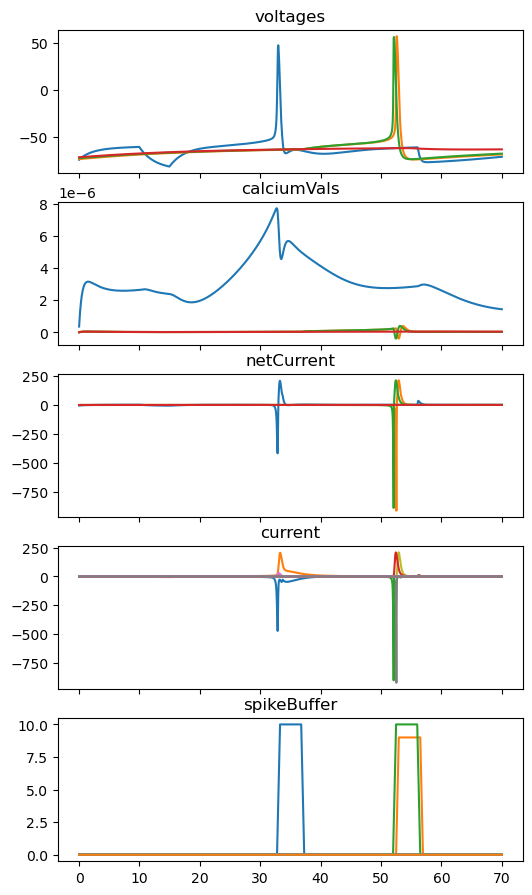

In [3]:
#theres different levels to this, each needs tools for simulating and testing
#channels
#spikers
#single compartment neurons
#multicompartment neurons
#neural populations 
#neural networks

#stimulate all ampa synapses on neuron 0?
#over write the spike output of neuron 1? 
#what you really need to be able to do is inject current into a specific neuron at a specific time point 
#which might mean that for the period of simulation you state exactly what the current value will be at each time point for every neuron 
#very memory inefficient, but might be fast on a gpu
#in python we specify the stimulation with indices and values for when the bias is anything other than the default value 
# bias overwrite as a parameter?

#new keys: spikerPreNeuron, spikerNeuronScale, nSpikers, channelPreSpiker (used to be preNeuron)

def solveNeurons(ac,biasOverWriteList,TS):
    #this function deals with determination of membrane voltage and calcium dynamics, 
    # i have moved spiking dynamics to the solveSpikers function 
    voltage = ac["voltages"]
    nNeurons = ac["nNeurons"]
    calciumVals = ac["calciumVals"]
    alpha = 1/(2*96485) #this is the conversion factor between current and Ca diffusion. scale it up if you want Ca in different units 
    CaEquilibriumVal = 0 #1 I think 1e-6 is reasonble, otsuka is 0
    CaRemovalRate = 2 #ms, this is the value otsuka uses, not sure where they get it from 
    for i in range(nNeurons):
        voltage[i] -= TS*(ac["netCurrent"][i]+ac["biasCurrents"][i]+biasOverWriteList[i])
        calciumVals[i] += TS*(-alpha*ac["netCaCurrent"][i] + (-calciumVals[i]+ CaEquilibriumVal)*CaRemovalRate) #This requires some explaination:
                        #We need to convert Ca current (in uA/cm^2) to Ca concentration (in mol/L) so I hardcode the conversion factor 
                        #Cellular Ca is tightly regulated to ~uM concentrations, so I've included a fixed point at 1e-6.
                        #I've set the timeconstant for Ca regulation to be 0.5ms, which might be a little fast
                        #With this implementation its possible to have 1. calcium efflux (which is fine), and 2. negative Ca concentrations (which is not fine)
                        #but negative Ca would require persistent Vm>140mV which is unphysiological anyway. 



#TODO: neurons have a spike buffer but spikers should also have a very small buffer
#TODO: spikers shouldnt be allowed a full buffer, too expensive
#TODO: neurons shouldnt be allowed have a buffer because some of them might not be axons
#NOTE: Solution. spikers get to have buffers and we will measure the performance impact to see if its significant
        
def solveSpikers(ac,TS):
    writeIndex = ac["writeIndex"]
    spikerPreNeuron = ac["spikerPreNeuron"] #this is the neuron that gets checked 
    spikerNeuronScale = ac["spikerNeuronScale"] #0 or 1
    voltages = ac["voltages"]
    spikeBuffer = ac["spikeBuffer"]
    nSpikers = ac["nSpikers"]
    spikerProbability = ac["spikerProbability"]
    for i in range(nSpikers):
        randomOutput = bool(np.random.random()<spikerProbability[i])
        spikeOutput =  bool(spikerNeuronScale[i]*int(voltages[spikerPreNeuron[i]]>0))  # here we could actually implement transmitter release and short term plasticity dynamics 
        spikeOutput = float(randomOutput or spikeOutput)                      # for now its very simple spike threshold 
        spikeBuffer[i][writeIndex[i]] = spikeOutput         
        writeIndex[i] = (writeIndex[i]+1)%ac["maxDelayInt"]


def solveChannels(ac,spikeOverwriteList,TS):
    nChannels = ac["nChannels"]
    voltage = ac["voltages"]
    calciumVals = ac["calciumVals"]
    writeIndex = ac["writeIndex"]
    maxDelay = ac["maxDelayInt"]

    for i in range(nChannels):
        postSynapticNeuron = ac["postNeuron"][i]
        V = voltage[postSynapticNeuron]
        Ca = calciumVals[postSynapticNeuron]
        preSynapticSpiker = ac["channelPreSpiker"][i] #for channel this is = to postSynaptic neuron, and does not matter
        #spikes = max(spikeVals[preSynapticSpiker],spikeOverwriteList[i])
        xs = ac["x"][i]
        xhs,xks = ac["vHalf"][i],ac["vKi"][i]
        xts0,xts1 = ac["tau0"][i],ac["tau1"][i]
        xths,xtks = ac["th"][i],ac["tkInv"][i]
        
        exponents = ac["exponent"][i]
        minOpenness = ac["minOpenness"][i]
        Erev = ac["Erev"][i]
        g0 = ac["conductance"][i]
        p = ac["efficacy"][i]
        w = ac["conductanceGain"][i]
        CaCurrent = ac["CaCurrent"][i]

        tempTS = TS
        gatingTotal = 1

        for j in range(len(xs)):
            x = xs[j]
            n = exponents[j]
            gatingTotal *= (x**n)

        g = g0 + w*p
        I = g*gatingTotal*(V-Erev) 
        ac["netCurrent"][postSynapticNeuron] += I
        ac["netCaCurrent"][postSynapticNeuron] += CaCurrent*I
        ac["current"][i] = I

        synapseDelay = ac["inputDelay"][i]
        readIndex = int((writeIndex[preSynapticSpiker]-synapseDelay)%maxDelay)
        perceivedSpike = ac["spikeBuffer"][preSynapticSpiker][readIndex]
        perceivedSpike = max(perceivedSpike,spikeOverwriteList[i])

        xs[0] = solveGate(xs[0],V,tempTS,xhs[0],xks[0],xts0[0],xts1[0],xths[0],xtks[0],minOpenness[0]) #gate1
        xs[1] = solveGate(xs[1],V,tempTS,xhs[1],xks[1],xts0[1],xts1[1],xths[1],xtks[1],minOpenness[1]) #gate2
        xs[2] = solveGate(xs[2],Ca,tempTS,xhs[2],xks[2],xts0[2],xts1[2],xths[2],xtks[2],minOpenness[2]) #CaGate
        xs[3] = solveGate(xs[3],perceivedSpike,tempTS,xhs[3],xks[3],xts0[3],xts1[3],xths[3],xtks[3],minOpenness[3]) #spikeGate

        dp = calcWeightChange(p,Ca,ac["rate"][i],ac["gammaP"][i],ac["gammaD"][i],ac["thetaP"][i],ac["thetaD"][i])
        ac["efficacy"][i]+=TS*dp

#TODO: update solveChannels to pull the spike from the correct location, and update genChannelData to provide the correct input 

def solveSystemStandard(ac,TS,runTime,stimInfoSpikes={},stimInfoCurrents= {},
                        recordingKeys = ["voltages","calciumVals","netCurrent","current","spikeBuffer"]):
    nIterations = int(runTime/TS)
    data = {key:[] for key in recordingKeys}
    tv = np.linspace(0,runTime,nIterations)
    nNeurons = ac["nNeurons"]
    nChannels = ac["nChannels"]
    for iteration,t in enumerate(tv):
        #calculate currents
        ac["netCurrent"] = np.zeros([nNeurons])
        ac["netCaCurrent"] = np.zeros([nNeurons])
        spikeOverwriteList = np.zeros(nChannels)
        biasOverWriteList = np.zeros(nNeurons)
        if iteration in stimInfoSpikes.keys():
            for syn in stimInfoSpikes[iteration]:
                spikeOverwriteList[syn] = 1
        if iteration in stimInfoCurrents.keys():
            for neur,val in stimInfoCurrents[iteration].items():
                biasOverWriteList[neur] = val

        #update the gates
        solveChannels(ac,spikeOverwriteList,TS)

        solveDiffusiveConnections(ac)

        solveNeurons(ac,biasOverWriteList,TS)

        solveSpikers(ac,TS)

        for key in data:
            data[key].append(deepcopy(ac[key]))

    for key in data:
        data[key] = np.array(data[key])
    data["time"] = tv
    return data



runTime = 70
stimInfoSpikes = {}
biasNeuron,biasVal = 0,10
st0,st1=10,15
st0,st1 = int(st0/TS),int(st1/TS)
stimInfoCurrents = {i:{biasNeuron:biasVal} for i in range(st0,st1)}
allChannelDataPy = deepcopy(allChannelData)
data = solveSystemStandard(allChannelDataPy,TS,runTime,stimInfoSpikes,stimInfoCurrents) 
standardPlot(data)

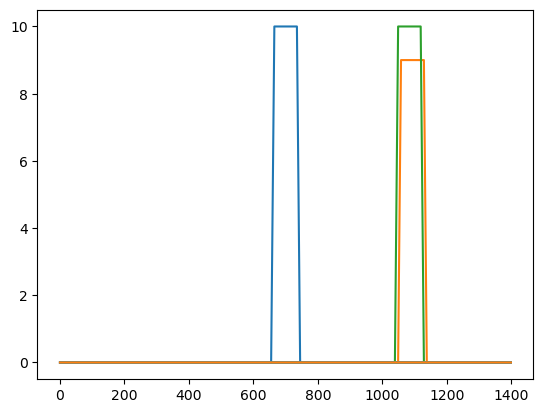

In [4]:
x = data["spikeBuffer"].sum(axis=2)
plt.plot(x);

[[False False  True ... False False False]
 [False False  True ... False False False]
 [False False  True ... False False False]
 ...
 [False False False ... False False False]
 [False False False ... False False False]
 [False False False ... False False False]]


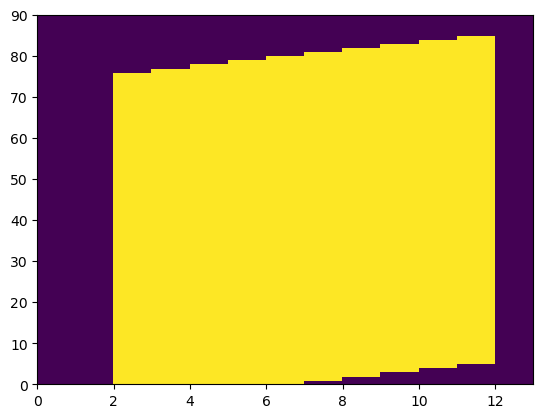

In [5]:
y = data["spikeBuffer"][660:750,0,14:27]
plt.pcolor(y)
print(y)